# `MLP e Backpropagation: Concrete Compressive Strength`

Duas implementações do backward:
- **Manual (NumPy)**: forward e backward escritos à mão, com as fórmulas do enunciado (δ, ∂L/∂W, ∂L/∂b) aparecendo literalmente no código.
- **PyTorch (autograd)**: mesma arquitetura, gradientes calculados automaticamente (usada só para conferir se os gradientes manuais estão corretos).

**Baseline**: 1 camada oculta, 16 neurônios, ReLU, entradas padronizadas, η=0,01, mini-batch=32, sem regularização, gradiente descendente puro.

**Comparações (C1-C4, ≥3 exigido pelo enunciado)**: C1 profundidade (1×2 camadas), C2 ativação (ReLU×tanh), C3 regularização (sem×com L2), C4 taxa de aprendizado (0,1/0,01/0,001). Bônus: largura e inicialização dos pesos.

### `Dupla:`

Anysabele de Paula Barbosa Santos

Millena Ferreira Marçal das Neves

In [ ]:
%matplotlib inline
import warnings, time
from copy import deepcopy
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
SEEDS = [0, 1, 2]

### `Dados: Concrete Compressive Strength`

UCI Machine Learning Repository (Yeh, 1998, DOI: 10.24432/C5PK67, CC BY 4.0). 1.030 amostras, 8 atributos de entrada, 1 alvo contínuo (resistência à compressão em MPa). Mesma base já usada e citada na apresentação 2.

Split 70/15/15 com semente fixa; o `StandardScaler` é ajustado só no treino (evita vazamento de dados). O conjunto de **teste é reservado para a avaliação final**: nenhuma escolha (hiperparâmetros, época de parada) usa o teste; isso é feito só com a validação.

In [ ]:
def load_concrete_data():
    url = "https://raw.githubusercontent.com/MillenaNeves/Neural-Networks/main/MLP%20Behavior%20in%20Regression%3A%20Sine%20Function%20and%20Concrete%20Compressive%20Strength/concrete_data.csv"
    df = pd.read_csv(url)
    feature_cols = [c for c in df.columns if c != "Compressive_Strength"]
    X = df[feature_cols].to_numpy(dtype=float)
    y = df["Compressive_Strength"].to_numpy(dtype=float).reshape(-1, 1)  # (N,1): saida linear de 1 neuronio
    return X, y, feature_cols


def split_indices(n, seed=42, train_frac=0.70, val_frac=0.15):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(n)
    n_train = int(round(train_frac * n))
    n_val = int(round(val_frac * n))
    return idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]


X, y, cols = load_concrete_data()
idx_tr, idx_val, idx_te = split_indices(len(X))
Xtr_raw, Xval_raw, Xte_raw = X[idx_tr], X[idx_val], X[idx_te]
ytr, yval, yte = y[idx_tr], y[idx_val], y[idx_te]

scaler = StandardScaler().fit(Xtr_raw)
Xtr, Xval, Xte = scaler.transform(Xtr_raw), scaler.transform(Xval_raw), scaler.transform(Xte_raw)

print(f"Concrete: {X.shape} | colunas: {cols}")
print(f"treino={len(Xtr)} val={len(Xval)} teste={len(Xte)}")

Concrete: (1030, 8) | colunas: ['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer', 'Coarse_Aggregate', 'Fine_Aggregate', 'Age']
treino=721 val=154 teste=155


### `Formulação do problema e justificativa das escolhas`

O alvo é uma quantidade contínua (resistência em MPa), então o problema é de **regressão**. Isso determina a camada de saída, a perda e as métricas:

| Elemento | Escolha | Por quê |
|---|---|---|
| Camada de saída | 1 neurônio **linear** (`a⁽ᴸ⁾ = z⁽ᴸ⁾`, `g' = 1`) | o alvo não é uma probabilidade nem uma classe: sigmoid/softmax limitariam a saída a [0, 1] |
| Função de perda | **MSE** | diferenciável, penaliza mais os erros grandes e dá o delta de saída `δ⁽ᴸ⁾ = (2/N)(ŷ − y)` |
| Ativação oculta | **ReLU** (baseline), comparada com **tanh** em C2 | ReLU é simples e não satura do lado positivo; tanh é suave e limitada a (−1, 1) |
| Métricas | **MAE**, **RMSE** e **R²** | MAE e RMSE estão na unidade do alvo (MPa), e o RMSE pesa mais os erros grandes; R² é a fração da variância explicada |

**Baseline** (ponto de partida fixo das comparações): 1 camada oculta de 16 neurônios (rede pequena para 8 atributos e 721 amostras de treino, rápida de treinar e fácil de inspecionar), inicialização He (variância `2/n_in`, calibrada para ReLU), η=0,01 e mini-lote de 32 (valores usuais para gradiente descendente puro).

### `MLP manual (NumPy): forward e backward explícitos`

Convenção: `X` tem shape `(N, n_in)` — amostras em linhas (padrão NumPy/sklearn). As fórmulas do enunciado são escritas para UMA amostra como vetor coluna; aqui aparecem vetorizadas para o lote inteiro:

| Uma amostra (enunciado) | Lote (este código) |
|---|---|
| `z^(l) = W^(l) a^(l-1) + b^(l)` | `Z^(l) = A^(l-1) @ W^(l) + b^(l)` |
| `δ^(l-1) = (W^(l))^T δ^(l) ⊙ g'(z^(l-1))` | `dZ^(l-1) = (dZ^(l) @ (W^(l))^T) * g'(Z^(l-1))` |
| `∂L/∂W^(l) = δ^(l) (a^(l-1))^T` | `dW^(l) = (A^(l-1))^T @ dZ^(l)` (somado no lote) |
| `∂L/∂b^(l) = δ^(l)` | `db^(l)` = soma de `dZ^(l)` nas linhas |

Cada LINHA de `Z`/`A`/`dZ` corresponde ao delta de UMA amostra (a versão vetorizada é só a fórmula do enunciado aplicada a todas as amostras do lote de uma vez).

In [ ]:
def init_weights(layer_sizes, scheme, seed):
    rng = np.random.default_rng(seed)
    W, b = [], []
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        if scheme == "naive":
            std = 0.01
        elif scheme == "xavier":
            std = np.sqrt(1.0 / n_in)
        elif scheme == "he":
            std = np.sqrt(2.0 / n_in)
        else:
            raise ValueError(scheme)
        W.append(rng.normal(0.0, std, size=(n_in, n_out)))
        b.append(np.zeros(n_out))
    return W, b


def _activate(z, name):
    if name == "relu":
        return np.maximum(0.0, z)
    if name == "tanh":
        return np.tanh(z)
    raise ValueError(name)


def _activate_deriv(z, name):
    if name == "relu":
        return (z > 0).astype(z.dtype)
    if name == "tanh":
        t = np.tanh(z)
        return 1.0 - t ** 2
    raise ValueError(name)


@dataclass
class ManualMLP:
    """MLP para regressao (saida linear) com forward/backward manuais."""
    layer_sizes: List[int]
    activation: str = "relu"
    init_scheme: str = "he"
    l2_lambda: float = 0.0
    seed: int = 0

    def __post_init__(self):
        self.n_layers = len(self.layer_sizes) - 1
        self.W, self.b = init_weights(self.layer_sizes, self.init_scheme, self.seed)

    def forward(self, X):
        A = X
        Zs, As = [], [A]
        for l in range(self.n_layers):
            Z = A @ self.W[l] + self.b[l]
            is_output = (l == self.n_layers - 1)
            A = Z if is_output else _activate(Z, self.activation)
            Zs.append(Z); As.append(A)
        return A, {"Z": Zs, "A": As}

    def mse(self, Y_hat, Y):
        """MSE puro (sem penalidade): usado nas curvas, no early stopping e nas metricas."""
        return np.mean((Y_hat - Y) ** 2)

    def loss(self, Y_hat, Y):
        """Objetivo otimizado: MSE + (lambda/N) * soma(||W||^2)  (vieses nao sao penalizados)."""
        N = Y.shape[0]
        reg_loss = 0.0
        if self.l2_lambda > 0:
            reg_loss = (self.l2_lambda / N) * sum(np.sum(Wl ** 2) for Wl in self.W)
        return self.mse(Y_hat, Y) + reg_loss

    def backward(self, Y, caches):
        """L = (1/N) sum (Y_hat-Y)^2  =>  delta^(saida) = (2/N)(Y_hat-Y)  (saida linear, g'=1)"""
        N = Y.shape[0]
        Zs, As = caches["Z"], caches["A"]
        grads_W = [None] * self.n_layers
        grads_b = [None] * self.n_layers
        delta_norms = [None] * self.n_layers

        Y_hat = As[-1]
        dZ = (2.0 / N) * (Y_hat - Y)

        for l in reversed(range(self.n_layers)):
            A_prev = As[l]
            delta_norms[l] = float(np.linalg.norm(dZ))
            dW = A_prev.T @ dZ
            db = np.sum(dZ, axis=0)
            if self.l2_lambda > 0:
                dW = dW + (2.0 * self.l2_lambda / N) * self.W[l]   # derivada da penalidade (lambda/N)*||W||^2
            grads_W[l] = dW; grads_b[l] = db
            if l > 0:
                dA_prev = dZ @ self.W[l].T
                dZ = dA_prev * _activate_deriv(Zs[l - 1], self.activation)

        return grads_W, grads_b, delta_norms

    def step(self, grads_W, grads_b, lr):
        """W <- W - eta dL/dW ,  b <- b - eta dL/db"""
        for l in range(self.n_layers):
            self.W[l] -= lr * grads_W[l]
            self.b[l] -= lr * grads_b[l]

    def predict(self, X):
        Y_hat, _ = self.forward(X)
        return Y_hat

### `Loop de treino (mini-batch, gradiente descendente puro)`

Sem Adam/momentum: só a regra do enunciado. Early stopping manual por paciência (30 épocas, máximo de 2000) sobre o MSE de validação, sem a penalidade L2 (restaura os melhores pesos ao final). Também registra: a norma média de δ por camada a cada época (diagnóstico de gradiente) e, se a taxa de aprendizado for alta demais e a rede divergir, a trajetória de perda por mini-lote da 1ª época em vez de travar com NaN.

In [ ]:
def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": float(np.sqrt(mse)),
            "R2": r2_score(y_true, y_pred)}


def train_mlp(model, X_train, y_train, X_val, y_val, lr=0.01, batch_size=32,
              max_epochs=2000, patience=30, seed=0):
    rng = np.random.default_rng(seed)
    n = X_train.shape[0]
    n_batches = int(np.ceil(n / batch_size))

    train_losses, val_losses = [], []
    delta_norms_per_layer = [[] for _ in range(model.n_layers)]
    first_epoch_batch_losses = []
    best_val, best_state, best_epoch, no_improve = np.inf, None, 0, 0
    initial_state = (deepcopy(model.W), deepcopy(model.b))
    diverged = False

    for epoch in range(max_epochs):
        perm = rng.permutation(n)
        epoch_delta_norms = [[] for _ in range(model.n_layers)]

        for bidx in range(n_batches):
            batch_idx = perm[bidx * batch_size:(bidx + 1) * batch_size]
            Xb, yb = X_train[batch_idx], y_train[batch_idx]

            y_hat, caches = model.forward(Xb)
            grads_W, grads_b, dnorms = model.backward(yb, caches)
            model.step(grads_W, grads_b, lr)
            for l in range(model.n_layers):
                epoch_delta_norms[l].append(dnorms[l])

            if epoch == 0:
                batch_loss = model.mse(model.forward(Xb)[0], yb)
                first_epoch_batch_losses.append(float(batch_loss) if np.isfinite(batch_loss) else np.nan)
                if not np.isfinite(batch_loss):
                    diverged = True
                    break
        if diverged:
            break

        train_loss = model.mse(model.forward(X_train)[0], y_train)
        val_loss = model.mse(model.forward(X_val)[0], y_val)
        if not (np.isfinite(train_loss) and np.isfinite(val_loss)):
            diverged = True
            break

        train_losses.append(train_loss); val_losses.append(val_loss)
        for l in range(model.n_layers):
            delta_norms_per_layer[l].append(float(np.mean(epoch_delta_norms[l])))

        if val_loss < best_val - 1e-7:
            best_val, best_epoch, no_improve = val_loss, epoch, 0
            best_state = (deepcopy(model.W), deepcopy(model.b))
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    if best_state is not None:
        model.W, model.b = best_state
    elif diverged:
        model.W, model.b = initial_state

    return {"train_losses": np.array(train_losses), "val_losses": np.array(val_losses),
            "delta_norms_per_layer": [np.array(d) for d in delta_norms_per_layer],
            "best_epoch": best_epoch, "n_epochs": len(train_losses), "diverged": diverged,
            "first_epoch_batch_losses": np.array(first_epoch_batch_losses)}

### `Exemplo numérico: forward, perda e backward passo a passo`

Um mini-lote de 3 amostras reais (já padronizadas) do treino, arquitetura baseline (8→16→1, ReLU), mostrando cada quantidade do enunciado com valores reais: `a⁽⁰⁾ → z⁽¹⁾ → a⁽¹⁾ → z⁽²⁾(=ŷ) → L → δ⁽²⁾ → ∂L/∂W⁽²⁾, ∂L/∂b⁽²⁾ → δ⁽¹⁾ → ∂L/∂W⁽¹⁾, ∂L/∂b⁽¹⁾`.

(A rede está com pesos recém-inicializados, não treinados, o objetivo aqui é mostrar o mecanismo, não uma boa previsão.)

In [ ]:
def print_array(name, arr, formula=""):
    arr = np.asarray(arr)
    preview = np.array2string(arr.ravel()[:4], precision=4, suppress_small=True)
    suffix = " ..." if arr.size > 4 else ""
    print(f"  {name:10s} shape={str(arr.shape):10s} ||.||={np.linalg.norm(arr):9.4f}   "
          f"primeiros valores={preview}{suffix}   {formula}")


X_batch, y_batch = Xtr[:3], ytr[:3]
model_demo = ManualMLP(layer_sizes=[8, 16, 1], activation="relu", init_scheme="he", seed=0)

print(f"Mini-lote: {X_batch.shape[0]} amostras, {X_batch.shape[1]} atributos padronizados.\n")
print(" FORWARD ")
print_array("a^(0) = X", X_batch, "(entrada = ativacao da camada 0)")
Y_hat, caches = model_demo.forward(X_batch)
for l in range(model_demo.n_layers):
    tag = "saida" if l == model_demo.n_layers - 1 else f"oculta {l+1}"
    print_array(f"z^({l+1})", caches["Z"][l], f"= a^({l}) W^({l+1}) + b^({l+1})  [camada {tag}]")
    print_array(f"a^({l+1})", caches["A"][l+1],
                "(saida linear: a=z)" if l == model_demo.n_layers-1 else f"= g(z^({l+1})), g=relu")

print("\n PERDA ")
L = model_demo.loss(Y_hat, y_batch)
print(f"  y (alvo real)    = {y_batch.ravel()}")
print(f"  y_hat (previsto) = {np.round(Y_hat.ravel(), 4)}")
print(f"  L = mean((y_hat-y)^2) = {L:.6f}")

print("\n BACKWARD ")
grads_W, grads_b, delta_norms = model_demo.backward(y_batch, caches)
for l in reversed(range(model_demo.n_layers)):
    tag = "saida" if l == model_demo.n_layers - 1 else f"oculta {l+1}"
    formula = ("delta^(L) = (2/N)(y_hat - y)   [saida linear, g'=1]" if l == model_demo.n_layers-1
               else f"delta^({l+1}) = (W^({l+2}))^T delta^({l+2}) (*) g'(z^({l+1}))")
    print(f"  [camada {tag}]  {formula}")
    print(f"     ||delta^({l+1})|| = {delta_norms[l]:.4f}")
    print_array(f"dL/dW^({l+1})", grads_W[l], f"= delta^({l+1}) (a^({l}))^T  (somado no lote)")
    print_array(f"dL/db^({l+1})", grads_b[l], f"= soma de delta^({l+1}) no lote")

print("\n ATUALIZAÇÃO (eta=0.01, ilustrativa) ")
eta = 0.01
for l in range(model_demo.n_layers):
    novo = model_demo.W[l].ravel()[0] - eta * grads_W[l].ravel()[0]
    print(f"  W^({l+1})[0,0]: {model_demo.W[l].ravel()[0]:.5f} - {eta}*({grads_W[l].ravel()[0]:.5f}) "
          f"= {novo:.5f}   (W <- W - eta dL/dW)")

Mini-lote: 3 amostras, 8 atributos padronizados.

 FORWARD 
  a^(0) = X  shape=(3, 8)     ||.||=   4.0082   primeiros valores=[-0.2743 -0.8787  0.678   0.4474] ...   (entrada = ativacao da camada 0)
  z^(1)      shape=(3, 16)    ||.||=   8.1651   primeiros valores=[ 0.5697  0.5358 -0.5558 -1.5843] ...   = a^(0) W^(1) + b^(1)  [camada oculta 1]
  a^(1)      shape=(3, 16)    ||.||=   6.5532   primeiros valores=[0.5697 0.5358 0.     0.    ] ...   = g(z^(1)), g=relu
  z^(2)      shape=(3, 1)     ||.||=   2.2787   primeiros valores=[0.2081 1.8298 1.342 ]   = a^(1) W^(2) + b^(2)  [camada saida]
  a^(2)      shape=(3, 1)     ||.||=   2.2787   primeiros valores=[0.2081 1.8298 1.342 ]   (saida linear: a=z)

 PERDA 
  y (alvo real)    = [41.16 28.94 21.6 ]
  y_hat (previsto) = [0.2081 1.8298 1.342 ]
  L = mean((y_hat-y)^2) = 940.803364

 BACKWARD 
  [camada saida]  delta^(L) = (2/N)(y_hat - y)   [saida linear, g'=1]
     ||delta^(2)|| = 35.4176
  dL/dW^(2)  shape=(16, 1)    ||.||= 126.4236   pri

### `Conferência: gradiente manual × PyTorch autograd`

Carrega os **mesmos pesos iniciais** num `nn.Sequential` equivalente, roda forward+backward nos **dois** (manual e autograd) no **mesmo** mini-lote, e compara. Diferenças de até ~`1e-14` (erro de arredondamento de ponto flutuante) são a evidência de que o backprop manual está matematicamente correto (não é aproximação, é a mesma conta).

A conferência usa os pesos iniciais, 1 mini-lote e **λ=0 (sem L2)**. O termo de L2 usado em C3 é a derivada direta da penalidade `(λ/N)·Σ‖W‖²`, isto é, `(2λ/N)·W`.

In [ ]:
def build_torch_equivalent(manual_model):
    """nn.Linear guarda o peso como (out,in) e calcula x @ W.T + b; o modelo
    manual guarda (in,out) e calcula x @ W + b - por isso a transposicao."""
    act_cls = nn.ReLU if manual_model.activation == "relu" else nn.Tanh
    layers = []
    for l in range(manual_model.n_layers):
        n_in, n_out = manual_model.layer_sizes[l], manual_model.layer_sizes[l+1]
        lin = nn.Linear(n_in, n_out, dtype=torch.float64)
        with torch.no_grad():
            lin.weight.copy_(torch.tensor(manual_model.W[l].T.copy()))
            lin.bias.copy_(torch.tensor(manual_model.b[l].copy()))
        layers.append(lin)
        if l < manual_model.n_layers - 1:
            layers.append(act_cls())
    return nn.Sequential(*layers)


def compare_gradients(manual_model, X, Y, verbose=True):
    Y_hat_manual, caches = manual_model.forward(X)
    grads_W, grads_b, _ = manual_model.backward(Y, caches)

    torch_model = build_torch_equivalent(manual_model)
    Xt = torch.tensor(X, dtype=torch.float64)
    Yt = torch.tensor(Y, dtype=torch.float64)
    Y_hat_torch = torch_model(Xt)
    loss_torch = nn.MSELoss(reduction="mean")(Y_hat_torch, Yt)
    torch_model.zero_grad(); loss_torch.backward()

    max_abs_diff = 0.0
    linear_layers = [m for m in torch_model if isinstance(m, nn.Linear)]
    for l, lin in enumerate(linear_layers):
        torch_dW = lin.weight.grad.numpy().T
        torch_db = lin.bias.grad.numpy()
        diff_W = np.max(np.abs(torch_dW - grads_W[l]))
        diff_b = np.max(np.abs(torch_db - grads_b[l]))
        max_abs_diff = max(max_abs_diff, diff_W, diff_b)
        if verbose:
            print(f"  camada {l}: max|dW_manual-dW_torch|={diff_W:.3e}   max|db_manual-db_torch|={diff_b:.3e}")
    if verbose:
        print(f"  perda: manual={manual_model.loss(Y_hat_manual, Y):.6f}  torch={loss_torch.item():.6f}")
    return max_abs_diff


rng = np.random.default_rng(0)
batch_idx = rng.choice(len(Xtr), size=32, replace=False)
Xb, yb = Xtr[batch_idx], ytr[batch_idx]

conf_rows = []
for arch_name, layer_sizes, act in [("baseline (1x16)", [8, 16, 1], "relu"),
                                     ("profundidade (2x16)", [8, 16, 16, 1], "relu"),
                                     ("tanh (1x16)", [8, 16, 1], "tanh")]:
    print(f"\n-- {arch_name}, ativacao={act} --")
    m = ManualMLP(layer_sizes=layer_sizes, activation=act, init_scheme="he", seed=0)
    max_diff = compare_gradients(m, Xb, yb)
    conf_rows.append({"arquitetura": arch_name, "ativacao": act, "max_diff_abs": max_diff})
    print(f"  -> maior diferenca absoluta entre TODOS os parametros: {max_diff:.3e}")

pd.DataFrame(conf_rows).to_csv(OUTPUT_DIR / "conferencia_gradientes_pytorch.csv", index=False)


-- baseline (1x16), ativacao=relu --
  camada 0: max|dW_manual-dW_torch|=3.553e-15   max|db_manual-db_torch|=7.105e-15
  camada 1: max|dW_manual-dW_torch|=7.105e-15   max|db_manual-db_torch|=0.000e+00
  perda: manual=1689.465214  torch=1689.465214
  -> maior diferenca absoluta entre TODOS os parametros: 7.105e-15

-- profundidade (2x16), ativacao=relu --
  camada 0: max|dW_manual-dW_torch|=1.776e-15   max|db_manual-db_torch|=1.776e-15
  camada 1: max|dW_manual-dW_torch|=3.553e-15   max|db_manual-db_torch|=1.776e-15
  camada 2: max|dW_manual-dW_torch|=1.421e-14   max|db_manual-db_torch|=0.000e+00
  perda: manual=1765.646705  torch=1765.646705
  -> maior diferenca absoluta entre TODOS os parametros: 1.421e-14

-- tanh (1x16), ativacao=tanh --
  camada 0: max|dW_manual-dW_torch|=3.553e-15   max|db_manual-db_torch|=5.329e-15
  camada 1: max|dW_manual-dW_torch|=7.105e-15   max|db_manual-db_torch|=1.421e-14
  perda: manual=1738.552418  torch=1738.552418
  -> maior diferenca absoluta entre T

### `Funções de plot`

In [ ]:
def plot_loss_curves(curves, title, ylabel="MSE", logy=True, save_name=None):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    colors = plt.cm.tab10.colors
    for i, (label, (tr, val)) in enumerate(curves.items()):
        c = colors[i % len(colors)]
        ax.plot(tr, color=c, linestyle="-", linewidth=1.6, label=f"{label} - treino")
        ax.plot(val, color=c, linestyle="--", linewidth=1.6, label=f"{label} - validacao")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("Epoca"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()


def plot_gradient_norms(delta_norms_dict, title, save_name=None):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    colors = plt.cm.tab10.colors
    styles = ["-", "--", ":", "-."]
    for i, (label, layer_norms) in enumerate(delta_norms_dict.items()):
        c = colors[i % len(colors)]
        for l, norms in enumerate(layer_norms):
            ax.plot(norms, color=c, linestyle=styles[l % len(styles)], linewidth=1.5,
                    label=f"{label} - camada {l+1}")
    ax.set_yscale("log")
    ax.set_xlabel("Epoca"); ax.set_ylabel("||delta|| medio (norma de Frobenius)")
    ax.set_title(title)
    ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()


def plot_divergence_trace(batch_losses, title, save_name=None):
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    finite_part = [v for v in batch_losses if np.isfinite(v)]
    ax.plot(range(1, len(finite_part) + 1), finite_part, "o-", color="crimson")
    ax.set_yscale("log")
    ax.set_xlabel("Mini-lote (dentro da 1a epoca)"); ax.set_ylabel("Perda (MSE) - escala log")
    ax.set_title(title); ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()


def plot_metric_by_group(results_df, group_col, metric_col, title, save_name=None):
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    groups = list(results_df[group_col].unique())
    data = [results_df.loc[results_df[group_col] == g, metric_col].to_numpy() for g in groups]
    ax.boxplot(data, labels=groups)
    ax.set_ylabel(metric_col); ax.set_title(title); ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()

### `Infraestrutura dos experimentos (config + runner)`

Cada execução (configuração × semente) registra as métricas de **treino, validação e teste** (MAE, RMSE, R²), a época escolhida e o **intervalo treino-validação**, definido como `MSE_val − MSE_treino` (em MPa²) na época escolhida pelo early stopping (a dos pesos restaurados). Nos logs e nas tabelas, `±`/`dp` é o desvio-padrão **amostral** (ddof=1) entre as 3 sementes (0, 1, 2).

In [ ]:
ALL_RUNS = []

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}")

@dataclass
class ExpConfig:
    name: str
    layer_sizes: List[int]
    activation: str = "relu"
    l2_lambda: float = 0.0
    lr: float = 0.01
    batch_size: int = 32
    init_scheme: str = "he"

    def as_row(self):
        return dict(name=self.name, layer_sizes=str(self.layer_sizes), activation=self.activation,
                    l2_lambda=self.l2_lambda, lr=self.lr, batch_size=self.batch_size,
                    init_scheme=self.init_scheme)

def run_one(cfg, Xtr, ytr, Xval, yval, Xte, yte, seed):
    model = ManualMLP(layer_sizes=cfg.layer_sizes, activation=cfg.activation,
                       init_scheme=cfg.init_scheme, l2_lambda=cfg.l2_lambda, seed=seed)
    res = train_mlp(model, Xtr, ytr, Xval, yval, lr=cfg.lr, batch_size=cfg.batch_size,
                     max_epochs=2000, patience=30, seed=seed)
    row = cfg.as_row()
    row.update(seed=seed, n_epocas=res["n_epochs"], melhor_epoca=res["best_epoch"], divergiu=res["diverged"])
    for split_name, Xs, ys in [("treino", Xtr, ytr), ("val", Xval, yval), ("teste", Xte, yte)]:
        for k, v in compute_metrics(ys, model.predict(Xs)).items():
            row[f"{k}_{split_name}"] = v
    # intervalo treino-validacao (MSE) na EPOCA ESCOLHIDA pelo early stopping (a dos pesos restaurados)
    be = res["best_epoch"]
    row["gap_train_val_mse"] = (float(res["val_losses"][be] - res["train_losses"][be])
                                 if len(res["train_losses"]) and not res["diverged"] else np.nan)
    return model, res, row

def run_group(group_name, variations, Xtr, ytr, Xval, yval, Xte, yte):
    representative = {}
    for label, cfg in variations.items():
        val_rmses = []
        for seed in SEEDS:
            model, res, row = run_one(cfg, Xtr, ytr, Xval, yval, Xte, yte, seed)
            row["grupo"], row["rotulo"] = group_name, label
            ALL_RUNS.append(row)
            if not res["diverged"]:
                val_rmses.append(row["RMSE_val"])
            if seed == SEEDS[0]:
                representative[label] = (model, res)
        if val_rmses:
            dp = np.std(val_rmses, ddof=1) if len(val_rmses) > 1 else 0.0   # desvio-padrao amostral
            log(f"  {group_name} | {label}: RMSE_val = {np.mean(val_rmses):.3f} +/- {dp:.3f} "
                f"({len(val_rmses)}/{len(SEEDS)} convergiram)")
        else:
            log(f"  {group_name} | {label}: DIVERGIU em todas as {len(SEEDS)} sementes")
    return representative

### `C1: Profundidade (1 × 2 camadas ocultas de 16)`

*Pergunta: uma rede mais profunda traz ganho consistente?*

[22:21:08]   C1_profundidade | 1 camada (baseline): RMSE_val = 6.664 +/- 0.338 (3/3 convergiram)
[22:21:08]   C1_profundidade | 2 camadas: RMSE_val = 7.323 +/- 1.167 (3/3 convergiram)


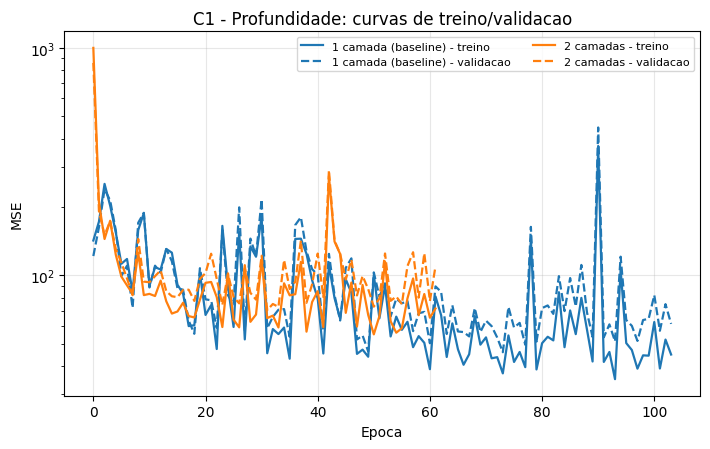

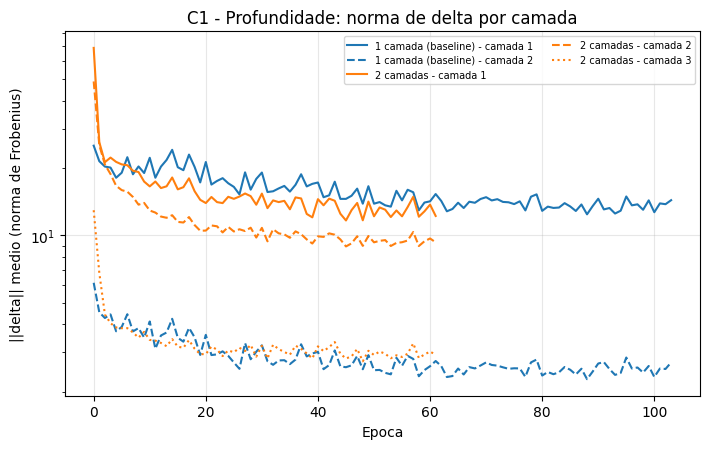

In [ ]:
c1 = run_group("C1_profundidade", {
    "1 camada (baseline)": ExpConfig("baseline", [8, 16, 1], "relu"),
    "2 camadas": ExpConfig("c1_2camadas", [8, 16, 16, 1], "relu"),
}, Xtr, ytr, Xval, yval, Xte, yte)

plot_loss_curves({k: (r["train_losses"], r["val_losses"]) for k, (_, r) in c1.items()},
                  "C1 - Profundidade: curvas de treino/validacao", save_name="c1_profundidade_curvas.png")
plot_gradient_norms({k: r["delta_norms_per_layer"] for k, (_, r) in c1.items()},
                     "C1 - Profundidade: norma de delta por camada", save_name="c1_profundidade_gradientes.png")

### `C2: Ativação (ReLU × tanh)`

*Pergunta: como mudou a convergência?*

[22:21:09]   C2_ativacao | ReLU (baseline): RMSE_val = 6.664 +/- 0.338 (3/3 convergiram)
[22:21:09]   C2_ativacao | tanh: RMSE_val = 6.079 +/- 0.233 (3/3 convergiram)


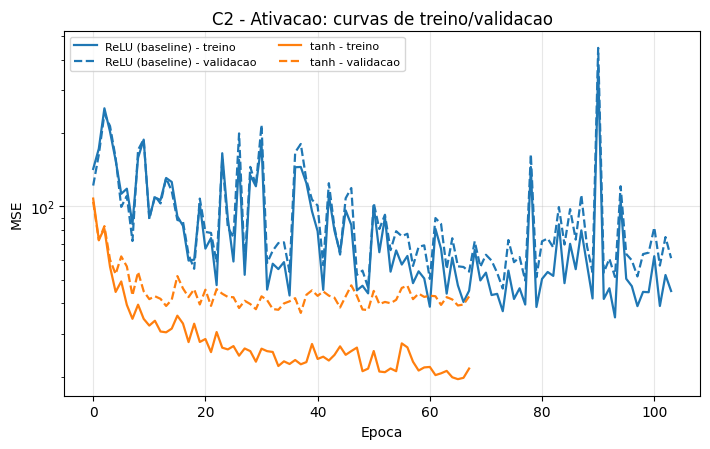

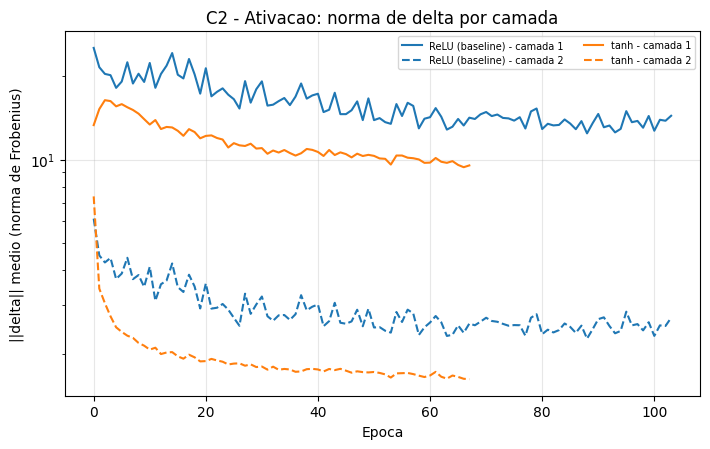

In [ ]:
c2 = run_group("C2_ativacao", {
    "ReLU (baseline)": ExpConfig("baseline", [8, 16, 1], "relu"),
    "tanh": ExpConfig("c2_tanh", [8, 16, 1], "tanh"),
}, Xtr, ytr, Xval, yval, Xte, yte)

plot_loss_curves({k: (r["train_losses"], r["val_losses"]) for k, (_, r) in c2.items()},
                  "C2 - Ativacao: curvas de treino/validacao", save_name="c2_ativacao_curvas.png")
plot_gradient_norms({k: r["delta_norms_per_layer"] for k, (_, r) in c2.items()},
                     "C2 - Ativacao: norma de delta por camada", save_name="c2_ativacao_gradientes.png")

### `C3: Regularização (sem × com L2)`

*Pergunta: o intervalo treino-validação diminuiu?*

L2 só nos pesos (vieses não são penalizados): `L = MSE + (λ/N)·Σ‖W‖²`, com λ=0,01 e N = tamanho do mini-lote (32). A derivada da penalidade é `(2λ/N)·W`, então a atualização é

`W ← W − η(∂MSE/∂W + (2λ/N)·W)`, com coeficiente efetivo `2λ/N = 6,25·10⁻⁴` (é o que `backward` faz).

O intervalo treino-validação é `MSE_val − MSE_treino` na época escolhida, sem a penalidade.

[22:21:10]   C3_regularizacao | sem L2 (baseline): RMSE_val = 6.664 +/- 0.338 (3/3 convergiram)
[22:21:10]   C3_regularizacao | com L2 (lambda=0.01): RMSE_val = 6.674 +/- 0.245 (3/3 convergiram)


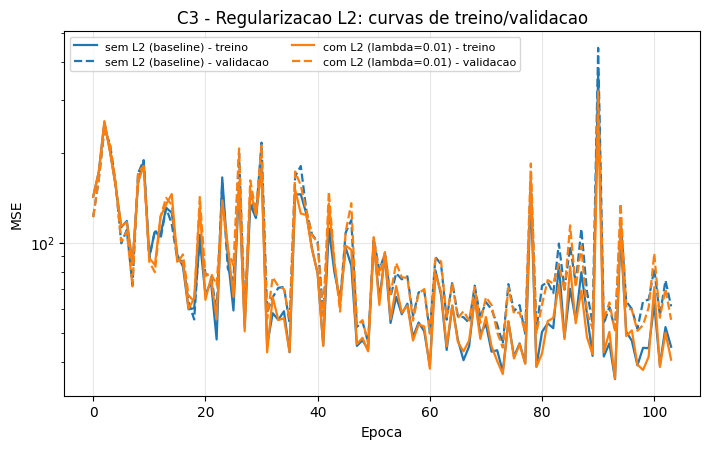

intervalo treino-val (MSE) por semente | sem L2 (baseline): [ 8.9 11.2  0.3]
intervalo treino-val (MSE) por semente | com L2 (lambda=0.01): [ 8.2 11.1  2.4]
penalidade L2 no gradiente = (lambda/N)*soma(W^2) = 0.116  vs  MSE de treino = 36.4  (0.32% da perda)


In [ ]:
c3 = run_group("C3_regularizacao", {
    "sem L2 (baseline)": ExpConfig("baseline", [8, 16, 1], "relu", l2_lambda=0.0),
    "com L2 (lambda=0.01)": ExpConfig("c3_l2", [8, 16, 1], "relu", l2_lambda=0.01),
}, Xtr, ytr, Xval, yval, Xte, yte)

plot_loss_curves({k: (r["train_losses"], r["val_losses"]) for k, (_, r) in c3.items()},
                  "C3 - Regularizacao L2: curvas de treino/validacao", save_name="c3_regularizacao_curvas.png")

# diagnostico para a pergunta do C3: intervalo por semente (na epoca escolhida) e escala da penalidade L2
for rot in ("sem L2 (baseline)", "com L2 (lambda=0.01)"):
    g = [r["gap_train_val_mse"] for r in ALL_RUNS if r["grupo"] == "C3_regularizacao" and r["rotulo"] == rot]
    print(f"intervalo treino-val (MSE) por semente | {rot}: {np.round(g, 1)}")
m_l2, r_l2 = c3["com L2 (lambda=0.01)"]                     # modelo da semente 0
soma_w2 = sum(np.sum(W ** 2) for W in m_l2.W)
pen = (m_l2.l2_lambda / 32) * soma_w2                       # 32 = tamanho do mini-lote (N no gradiente)
mse_tr = r_l2["train_losses"][r_l2["best_epoch"]]
print(f"penalidade L2 no gradiente = (lambda/N)*soma(W^2) = {pen:.3f}  vs  MSE de treino = {mse_tr:.1f}  "
      f"({100 * pen / mse_tr:.2f}% da perda)")

### `C4: Taxa de aprendizado (η = 0,1 / 0,01 / 0,001)`

*Pergunta: houve lentidão ou instabilidade?* Com gradiente descendente puro (sem Adam), η=0,1 é esperado divergir, o código detecta isso e registra a trajetória de perda por mini-lote em vez de travar.

[22:21:11]   C4_aprendizado | eta=0.1: DIVERGIU em todas as 3 sementes
[22:21:11]   C4_aprendizado | eta=0.01 (baseline): RMSE_val = 6.664 +/- 0.338 (3/3 convergiram)
[22:21:11]   C4_aprendizado | eta=0.001: RMSE_val = 6.263 +/- 0.070 (3/3 convergiram)


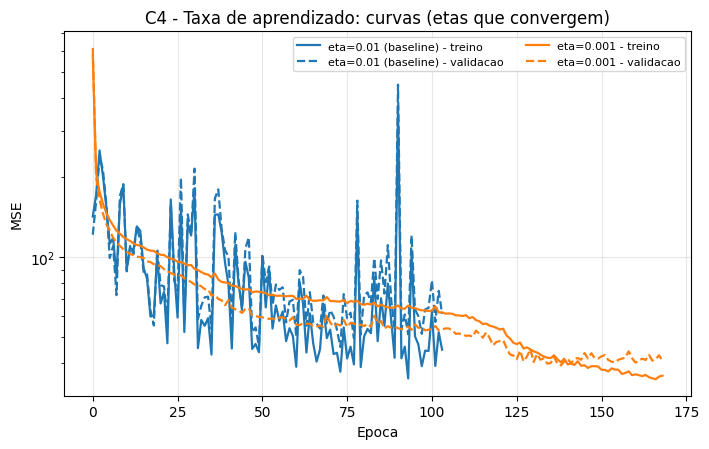

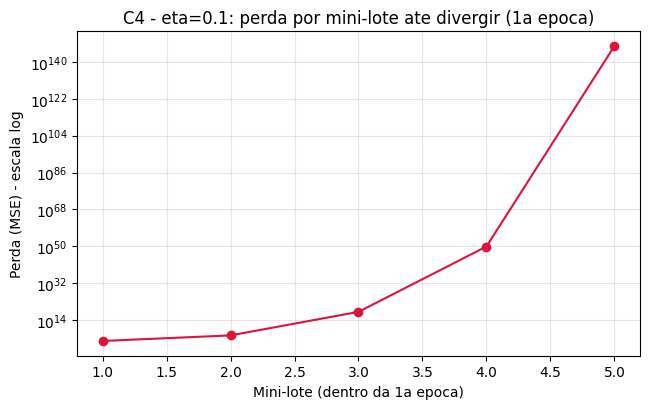

In [ ]:
c4 = run_group("C4_aprendizado", {
    "eta=0.1": ExpConfig("c4_lr01", [8, 16, 1], "relu", lr=0.1),
    "eta=0.01 (baseline)": ExpConfig("baseline", [8, 16, 1], "relu", lr=0.01),
    "eta=0.001": ExpConfig("c4_lr0001", [8, 16, 1], "relu", lr=0.001),
}, Xtr, ytr, Xval, yval, Xte, yte)

curves_c4 = {k: (r["train_losses"], r["val_losses"]) for k, (_, r) in c4.items() if not r["diverged"]}
plot_loss_curves(curves_c4, "C4 - Taxa de aprendizado: curvas (etas que convergem)",
                  save_name="c4_aprendizado_curvas.png")

_, res_divergente = c4["eta=0.1"]
plot_divergence_trace(res_divergente["first_epoch_batch_losses"],
                       "C4 - eta=0.1: perda por mini-lote ate divergir (1a epoca)",
                       save_name="c4_divergencia_eta01.png")

### `Bônus: Largura e inicialização dos pesos`

Inicializações comparadas: `naive` = normal com desvio 0,01; `xavier` = variante *fan-in*, desvio `√(1/n_in)` (o Glorot original usa `√(2/(n_in+n_out))`); `he` = desvio `√(2/n_in)`.

[22:21:12]   BONUS_largura | 8 neuronios: RMSE_val = 6.965 +/- 0.262 (3/3 convergiram)
[22:21:12]   BONUS_largura | 16 neuronios (baseline): RMSE_val = 6.664 +/- 0.338 (3/3 convergiram)
[22:21:13]   BONUS_largura | 32 neuronios: RMSE_val = 6.130 +/- 0.468 (3/3 convergiram)


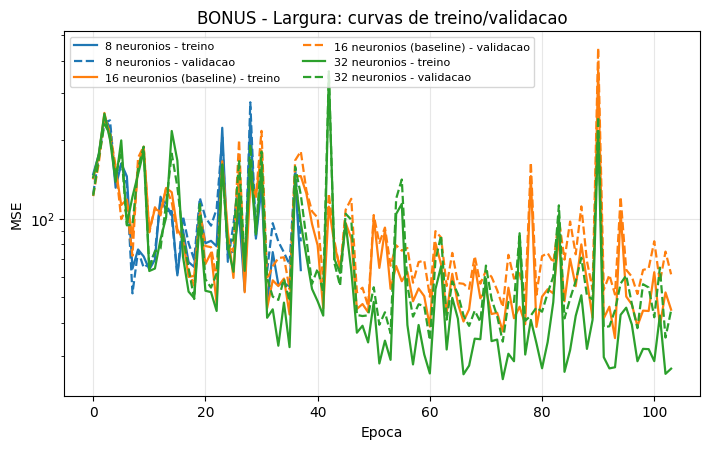

[22:21:14]   BONUS_inicializacao | ingenua (desvio 0.01): RMSE_val = 5.497 +/- 0.337 (3/3 convergiram)
[22:21:14]   BONUS_inicializacao | Xavier (fan-in): RMSE_val = 6.523 +/- 0.736 (3/3 convergiram)
[22:21:15]   BONUS_inicializacao | He (baseline p/ ReLU): RMSE_val = 7.323 +/- 1.167 (3/3 convergiram)


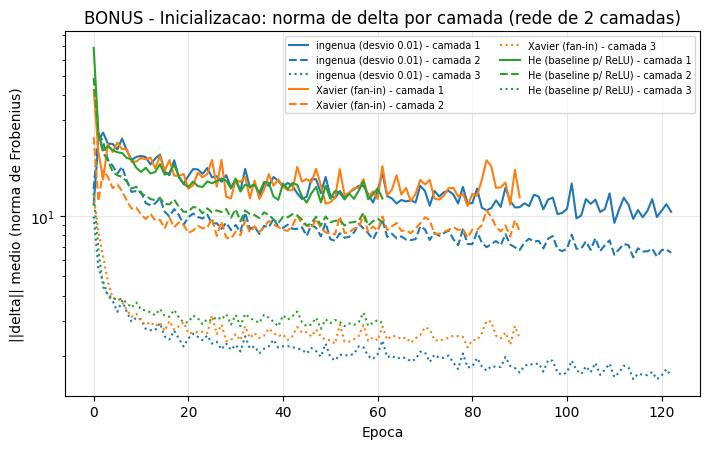

In [ ]:
bonusA = run_group("BONUS_largura", {
    "8 neuronios": ExpConfig("bonusA_8", [8, 8, 1], "relu"),
    "16 neuronios (baseline)": ExpConfig("baseline", [8, 16, 1], "relu"),
    "32 neuronios": ExpConfig("bonusA_32", [8, 32, 1], "relu"),
}, Xtr, ytr, Xval, yval, Xte, yte)
plot_loss_curves({k: (r["train_losses"], r["val_losses"]) for k, (_, r) in bonusA.items()},
                  "BONUS - Largura: curvas de treino/validacao", save_name="bonus_largura_curvas.png")

bonusB = run_group("BONUS_inicializacao", {
    "ingenua (desvio 0.01)": ExpConfig("bonusB_naive", [8, 16, 16, 1], "relu", init_scheme="naive"),
    "Xavier (fan-in)": ExpConfig("bonusB_xavier", [8, 16, 16, 1], "relu", init_scheme="xavier"),
    "He (baseline p/ ReLU)": ExpConfig("bonusB_he", [8, 16, 16, 1], "relu", init_scheme="he"),
}, Xtr, ytr, Xval, yval, Xte, yte)
plot_gradient_norms({k: r["delta_norms_per_layer"] for k, (_, r) in bonusB.items()},
                     "BONUS - Inicializacao: norma de delta por camada (rede de 2 camadas)",
                     save_name="bonus_inicializacao_gradientes.png")

### `Tabelas finais`

Uma linha por configuração, com a **configuração e os resultados** lado a lado (média das sementes que convergiram; `dp` = desvio-padrão amostral, ddof=1; mini-lote = 32 em todas). Validação e **teste** aparecem juntos: a validação escolheu a época (early stopping) e serviu para comparar as configurações; o **teste só é reportado aqui, como avaliação final**. `gap_treino_val` = `MSE_val − MSE_treino` (MPa²) na época escolhida; `n_divergiu` = nº de sementes que divergiram (η=0,1 não tem métricas porque divergiu nas 3).

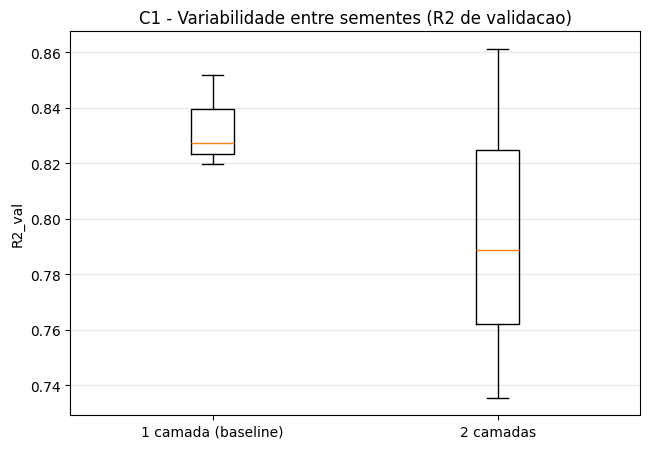

[22:21:15] Concluido. 45 execucoes registradas (3 divergiram - esperado para eta=0.1).


,grupo,rotulo,arquitetura,ativacao,l2_lambda,eta,inicializacao,n_divergiu,RMSE_treino,RMSE_val,RMSE_val_dp,RMSE_teste,RMSE_teste_dp,MAE_val,MAE_teste,R2_val,R2_teste,gap_treino_val,epocas
0,C1_profundidade,1 camada (baseline),"[8, 16, 1]",relu,0.00,0.010,he,0,6.140,6.664,0.338,6.174,0.117,5.181,4.905,0.833,0.862,6.788,96.000
1,C1_profundidade,2 camadas,"[8, 16, 16, 1]",relu,0.00,0.010,he,0,6.624,7.323,1.167,7.408,0.809,5.745,5.756,0.795,0.800,9.416,95.333
2,C2_ativacao,ReLU (baseline),"[8, 16, 1]",relu,0.00,0.010,he,0,6.140,6.664,0.338,6.174,0.117,5.181,4.905,0.833,0.862,6.788,96.000
3,C2_ativacao,tanh,"[8, 16, 1]",tanh,0.00,0.010,he,0,4.783,6.079,0.233,5.858,0.270,4.582,4.480,0.861,0.876,14.073,71.333
4,C3_regularizacao,sem L2 (baseline),"[8, 16, 1]",relu,0.00,0.010,he,0,6.140,6.664,0.338,6.174,0.117,5.181,4.905,0.833,0.862,6.788,96.000
5,C3_regularizacao,com L2 (lambda=0.01),"[8, 16, 1]",relu,0.01,0.010,he,0,6.110,6.674,0.245,6.079,0.054,5.176,4.800,0.832,0.866,7.249,96.000
6,C4_aprendizado,eta=0.1,"[8, 16, 1]",relu,0.00,0.100,he,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,C4_aprendizado,eta=0.01 (baseline),"[8, 16, 1]",relu,0.00,0.010,he,0,6.140,6.664,0.338,6.174,0.117,5.181,4.905,0.833,0.862,6.788,96.000
8,C4_aprendizado,eta=0.001,"[8, 16, 1]",relu,0.00,0.001,he,0,6.347,6.263,0.070,6.618,0.165,4.980,5.168,0.853,0.841,-1.074,165.333
9,BONUS_largura,8 neuronios,"[8, 8, 1]",relu,0.00,0.010,he,0,7.210,6.965,0.262,6.984,0.837,5.399,5.358,0.818,0.822,-3.878,56.000


In [ ]:
pd.set_option("display.max_columns", None)

df_all = pd.DataFrame(ALL_RUNS)
df_all.to_csv(OUTPUT_DIR / "tabela_configuracoes_completa.csv", index=False)

df_converged = df_all[~df_all["divergiu"]]
chaves = ["grupo", "rotulo"]

# configuracao (constante dentro de cada grupo/rotulo) e quantas sementes divergiram
cfg_cols = (df_all.groupby(chaves, sort=False)
            .agg(arquitetura=("layer_sizes", "first"), ativacao=("activation", "first"),
                 l2_lambda=("l2_lambda", "first"), eta=("lr", "first"),
                 inicializacao=("init_scheme", "first"), n_divergiu=("divergiu", "sum")))

# resultados: media das sementes que convergiram (dp = desvio-padrao amostral, ddof=1)
res_cols = (df_converged.groupby(chaves, sort=False)
            .agg(RMSE_treino=("RMSE_treino", "mean"),
                 RMSE_val=("RMSE_val", "mean"), RMSE_val_dp=("RMSE_val", "std"),
                 RMSE_teste=("RMSE_teste", "mean"), RMSE_teste_dp=("RMSE_teste", "std"),
                 MAE_val=("MAE_val", "mean"), MAE_teste=("MAE_teste", "mean"),
                 R2_val=("R2_val", "mean"), R2_teste=("R2_teste", "mean"),
                 gap_treino_val=("gap_train_val_mse", "mean"), epocas=("n_epocas", "mean")))

resumo = cfg_cols.join(res_cols).reset_index()
resumo.to_csv(OUTPUT_DIR / "tabela_resumo_por_config.csv", index=False)

plot_metric_by_group(df_converged[df_converged["grupo"] == "C1_profundidade"], "rotulo", "R2_val",
                      "C1 - Variabilidade entre sementes (R2 de validacao)",
                      save_name="c1_variabilidade_boxplot.png")

log(f"Concluido. {len(df_all)} execucoes registradas ({int(df_all['divergiu'].sum())} divergiram - "
    f"esperado para eta=0.1).")
resumo.round(3)

### `Conclusão`

**Foco da atividade**: entender o caminho forward → perda → backward → atualização e sustentar as conclusões com comparações controladas (um fator por vez, 3 sementes), olhando validação **e** teste. A conferência com o PyTorch valida a implementação manual: os gradientes bateram com o autograd com diferença máxima de ~1e-14 (arredondamento de ponto flutuante) nas 3 arquiteturas testadas (pesos iniciais, 1 mini-lote, sem L2).

**Achados** (RMSE em MPa, média de 3 sementes; validação → teste):
- **C1 (profundidade)**: 2 camadas piorou (6,66 → 7,32 na validação; 6,17 → 7,41 no teste) e com mais variância entre sementes. O erro de treino também piorou (RMSE 6,14 → 6,62), ou seja, a rede mais profunda nem ajusta melhor o treino. O gráfico de norma de delta por camada não mostra um colapso dramático (vanishing gradient severo); o problema parece ser dificuldade geral de otimização com gradiente descendente puro (sem taxa adaptativa), não sumiço de gradiente per se.
- **C2 (ativação)**: tanh convergiu de forma mais estável que ReLU nas curvas (ReLU oscila bastante) e ficou melhor na validação (6,08) e no teste (5,86), plausivelmente porque a saída ilimitada da ReLU (sem saturação do lado positivo) produz gradientes maiores e mais variáveis lote a lote, enquanto o g'(z) saturante do tanh modera as atualizações (hipótese, não testada aqui). Em contrapartida, o tanh tem o maior intervalo treino-validação de C1–C4 (14,1 contra 6,8 da ReLU): ajusta melhor o treino (RMSE 4,78), com sinal de início de overfitting.
- **C3 (L2)**: sem efeito mensurável com λ=0,01. As curvas ficam sobrepostas e o RMSE quase não muda (validação 6,66 → 6,67; teste 6,17 → 6,08), sem diferença que se destaque do desvio entre sementes. O intervalo treino-validação não diminuiu (6,8 → 7,2; por semente, [8,9; 11,2; 0,3] → [8,2; 11,1; 2,4]): é dominado pela variação entre sementes. A causa é a escala da penalidade: (λ/N)·Σ‖W‖² ≈ 0,12 contra um MSE de treino ≈ 36 (0,3% da perda).
- **C4 (taxa)**: η=0,1 diverge (evidência: `c4_divergencia_eta01.png`; a perda vai de 7,7·10³ a 4,9·10¹⁴⁷ em 5 mini-lotes e o 6º já dá NaN). η=0,001 converge mais devagar (165 épocas contra 96) e com curvas bem mais suaves. Na validação ficou melhor e com menor variância entre sementes (6,26 ± 0,07 contra 6,66 ± 0,34), **mas no teste ficou pior** (6,62 contra 6,17) e sem menor variância (dp 0,17 contra 0,12): o ganho da validação não se confirmou no teste. O intervalo negativo (−1,1; erro de treino maior que o de validação) indica treino ainda lento (underfitting), não overfitting.
- **Bônus largura**: mais neurônios reduzem o erro de treino de forma consistente (RMSE 7,21 → 6,14 → 5,48 para 8/16/32) e melhoram a validação (6,97 → 6,66 → 6,13). No teste, 8 → 16 melhora (6,98 → 6,17), mas 16 e 32 praticamente empatam (6,17 e 6,10), com variância alta para 32 (dp 0,82 contra 0,12).
- **Bônus inicialização**: contra a expectativa de que He seria melhor para ReLU, a inicialização "ingênua" (desvio 0,01) saiu na frente nesta rede de 2 camadas, na validação (5,50 contra 7,32 da He) e no teste (5,49 contra 7,41); a Xavier fica no meio. As normas de delta por camada ficam parecidas entre os esquemas, então a diferença provavelmente vem de ONDE cada inicialização começa na paisagem de perda, não da magnitude do gradiente em si (hipótese, não testada aqui).

**Sinais de under/overfitting** (intervalo = `MSE_val − MSE_treino`, em MPa², na época escolhida): o baseline tem erro de treino ainda alto (RMSE 6,1 MPa, contra 4,3 da inicialização ingênua) e intervalo moderado (6,8), ou seja, mais limitação de otimização/capacidade (underfitting) do que overfitting. Intervalos negativos (η=0,001: −1,1; largura 8: −3,9) indicam underfitting. Intervalos grandes e positivos (tanh: 14,1; inicialização ingênua: 12,0) indicam início de overfitting, embora esses estejam entre os modelos com menor erro em validação e teste.

**Limitações**: 3 sementes e um único split 70/15/15 (154 amostras de validação e 155 de teste), então as estimativas de RMSE são ruidosas e diferenças de poucas décimas são tendência, não prova (em C4, validação e teste até invertem o ranking); o baseline (η=0,01, gradiente descendente puro) oscila bastante, o que aumenta a variância; padronização, mini-lote (32) e critério de parada foram mantidos fixos, não comparados; o L2 foi testado com um único λ, pequeno nessa escala.

**Possíveis melhorias**: taxa de aprendizado adaptativa (Adam) ou decaimento de η para reduzir a oscilação; padronizar também o alvo; mais sementes ou validação cruzada para estimar melhor a variabilidade; λ maiores para o L2 ter efeito visível.